# K-NN. Algoritmo k-Nearest Neighbors.

Es un método que simplemente *busca en las observaciones más cercanas a la que se está tratando de predecir* y clasifica el punto de interés basado en la mayoría de datos que le rodean. Es un algoritmo:

- **Supervisado**: tenemos etiquetado nuestro conjunto de datos de entrenamiento, con la clase o resultado esperado dada “una fila” de datos.
- **Basado en Instancia**: el algoritmo no aprende explícitamente un modelo (como por ejemplo en Regresión Logística o árboles de decisión). En cambio memoriza las instancias de entrenamiento que son usadas como “base de conocimiento” para la fase de predicción.

Aplicable en problemas de *sistemas de recomendación*, *búsqueda semántica* y *detección de anomalías*.

### Ventajas e inconvenientes.    

Como ventaja destacar que es sencillo de aprender e implementar. 
Como inconvenientes, el hecho de utilizar todo el dataset para entrenar “cada punto” y lo que eso supone en uso de  memoria y recursos de procesamiento elevados. Por ello, este algoritmo suele funcionar mejor en datasets pequeños y sin una cantidad enorme de características (variables/columnas).

## Funcionamiento del algoritmo k-NN    

El algoritmo funciona siguiendo esta secuencia:

1 - Calcular la distancia entre el item a clasificar y el resto de items del dataset de entrenamiento.   
2 - Seleccionar los “k” elementos más cercanos (con menor distancia, según la función que se use)   
3 - Realizar una “votación de mayoría” entre los k puntos: los de una clase/etiqueta que **dominen** decidirán su clasificación final.     

Teniendo en cuenta el punto 3, se ve que para decidir la clase de un punto *es muy importante el valor de k*, pues este terminará casi por definir a qué grupo pertenecerán los puntos, sobre todo en las “fronteras” entre grupos. Por ejemplo -y a priori- se podría elegir valores impares de k para desempatar (si las características que utilizamos son pares). No será lo mismo tomar para decidir 3 valores que 13. Esto no quiere decir que necesariamente tomar más puntos implique mejorar la precisión. Lo que es seguro es que cuantos más “puntos k”, más tardará el algoritmo en procesar y dar respuesta.   

En este ejemplo, tomamos **k=3**.

<img src="./img/knn_1.jpg" width=275>
<img src="./img/knn_2.jpg" width=275>
<img src="./img/knn_3.jpg" width=275>
<img src="./img/knn_4.jpg" width=275>
<img src="./img/knn_5_ok.jpg" width=275>       

Pero, ¿qué sucede si incrementamos el valor de **k** y tomamos ahora el valor **5**?     

<img src="./img/knn_k5_1.jpg" width=275>
<img src="./img/knn_5.jpg" width=275>     

Cómo ya se ha comentado, dependiendo del valor de ***k*** se pueden obtener resultados diferentes para cada situación.    

## Cómo elegir el mejor valor para **k**    

Para elegir el mejor valor *k*, como se ha visto, es necesario probar con algunos valores para dar con ***el valor k que genere las predicciones más exactas con la menor cantidad de errores***. Determinar el mejor valor es un ejercicio de equilibrio:

Si se escoge un valor pequeño para **k**, el modelo se ajusta mucho a los datos y se vuelve muy sensible e inestable. Por ejemplo, tomando k=1 se corre el riesgo de que un dato mal etiquetado genere una predicción incorrecta.      
Por otro lado, si se selecciona un valor de **k** demasidado elevado, el modelo tiende a 'suavizar' la predicción y considerar vecinos de clases distintas, afectando a la precisión de esta predicción.

Determinar un valor de **k** adecuado supone, como se puede intuir, realizar distintas pruebas, a ser posible, utilizando la técnica de *"validación cruzada"*.

### Cálculo de la distancia.

Otro factor importante en el comportamiento de este algoritmo es el tipo de *cálculo de distancia* a utilizar por este.   

Las formas más populares de “calcular la distancia" entre puntos son la distancia *"Euclidiana"* (la “de siempre”), la distancia *"Manhattan"* (geometría del taxi) o la [distancia de *"Hamming"*](https://es.wikipedia.org/wiki/Distancia_de_Hamming) (métrica de superposición, que mide la distancia entre dos cadenas de igual longitud) entre otras.    
Recordemos que este algoritmo -y prácticamente todos en ML- funcionan mejor con varias características de las que tomemos datos (las columnas del dataset). Lo que se entiende como “distancia” en la vida real, quedará "abstracto" a muchas dimensiones que no es posible “visualizar” fácilmente (como por ejemplo en un mapa).

Por último, es importante considerar el **escalado de variables** para evitar que aquellas variables que estén en rangos más amplios que el resto no supongan un factor dominante en los cálculos de distancias, perjudicando con la posible distorsión de predicciones.

#### "Maldición de la dimensionalidad"    

Si el dataset dispone de un número muy elevado de características, todos los datos acaban estando a igual distancia unos de otros, siendo imposible aplicar la técnica del "vecino más cercano". Esto hace que el algoritmo no sea capaz de generar predicciones correctas.      
Para evitar esto se suele reducir dimensiones aplicando, por ejemplo, una selección de las variables más "decisivas" del dataset antes de aplicar el algoritmo. 

## Ejemplo de uso del algoritmo k-NN en clasificación

### Predicción de Incendios Forestales.    

Este conjunto de datos simula un estudio sobre la probabilidad de incendios en zonas forestales y contiene 1000 observaciones. Cada observación representa una zona geográfica en un momento determinado e incluye parámetros ambientales que pueden influir en la aparición de incendios.

Incluye 8 atributos, además del atributo que se quiere predecir (fire). Los valores de los atributos han sido generados para reflejar condiciones meteorológicas y ambientales que desempeñan un papel clave en la propagación de incendios.

#### **Las características de cada muestra son:**

- `temperature`: Temperatura ambiental en grados Celsius (°C)
- `humidity`: Porcentaje de humedad relativa en el aire (%)
- `wind_speed`: Velocidad del viento en km/h
- `precipitation`: Cantidad de precipitación acumulada en las últimas 24 horas (mm)
- `soil_dryness`: Índice de sequedad del suelo (0–100), donde 100 representa un suelo extremadamente seco
- `forest_density`: Porcentaje de cobertura forestal en la zona analizada (0.1–1.0)
- `sun_hours`: Número de horas de sol al día

#### **Atributo a predecir**

- `fire`: Indica si se ha producido un incendio en la zona  
  - `no_fire` = 0 (no se ha producido incendio)  
  - `fire` = 1 (incendio detectado)

#### 1. - Importamos librerías

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler

from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

from sklearn.metrics import accuracy_score, precision_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import seaborn as sns
import matplotlib.pyplot as plt

In [25]:
import warnings
warnings.filterwarnings("ignore")

#### 2.- Carga del dataset

In [10]:
df = pd.read_csv(filepath_or_buffer='./datasets/wildfires.csv', sep=',', header=0)
df

,temperature,humidity,wind_speed,precipitation,soil_dryness,forest_density,sun_hours,fire
0,24.932771,29.237345,19.409151,31.720442,73.013363,0.682059,10.956946,no_fire
1,27.816982,55.706771,12.675036,25.977470,53.239811,0.460108,5.666198,no_fire
2,23.800353,57.928352,20.059318,32.772818,41.862009,0.449017,6.084841,fire
3,26.354897,47.184982,21.314765,12.959491,75.501170,0.497959,9.747597,fire
4,28.695189,58.471316,18.920163,33.485641,56.694146,0.468986,3.981641,no_fire
...,...,...,...,...,...,...,...,...
4995,24.183230,66.719747,19.419238,25.241275,24.267348,0.277676,7.510502,fire
4996,22.346014,39.082334,22.034633,30.920179,72.483091,0.670347,8.263846,no_fire
4997,26.139203,41.845262,9.765746,27.494043,65.220841,0.616424,7.154270,no_fire
4998,25.250211,45.111600,10.733052,26.153297,65.566847,0.608658,6.447664,no_fire


#### 3.- Información del dataset

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   temperature     5000 non-null   float64
 1   humidity        5000 non-null   float64
 2   wind_speed      5000 non-null   float64
 3   precipitation   5000 non-null   float64
 4   soil_dryness    5000 non-null   float64
 5   forest_density  5000 non-null   float64
 6   sun_hours       5000 non-null   float64
 7   fire            5000 non-null   str    
dtypes: float64(7), str(1)
memory usage: 312.6 KB


#### 4.- Selección de características.   

En este caso, no se elimina ninguna de las columnas.

#### 5.- Gestión de valores nulos

In [12]:
print(df.isnull().sum())

temperature       0
humidity          0
wind_speed        0
precipitation     0
soil_dryness      0
forest_density    0
sun_hours         0
fire              0
dtype: int64


Comprobamos que, en esta ocasión, el dataset no contiene valores faltantes/nulos

#### 6.- Comprobación valores existentes en la columna etiqueta/target (**'fire'**)

In [13]:
print(df['fire'].unique())

<StringArray>
['no_fire', 'fire']
Length: 2, dtype: str


#### 7.- Existencia de duplicados.   

In [14]:
print("Filas duplicadas: ", df.duplicated().sum())

Filas duplicadas:  0


#### 8. Distribución de datos.    

Para esta ocasión, usaremos `scipy.stats` de la librería `scipy` para calcular las distribuciones de los datos.

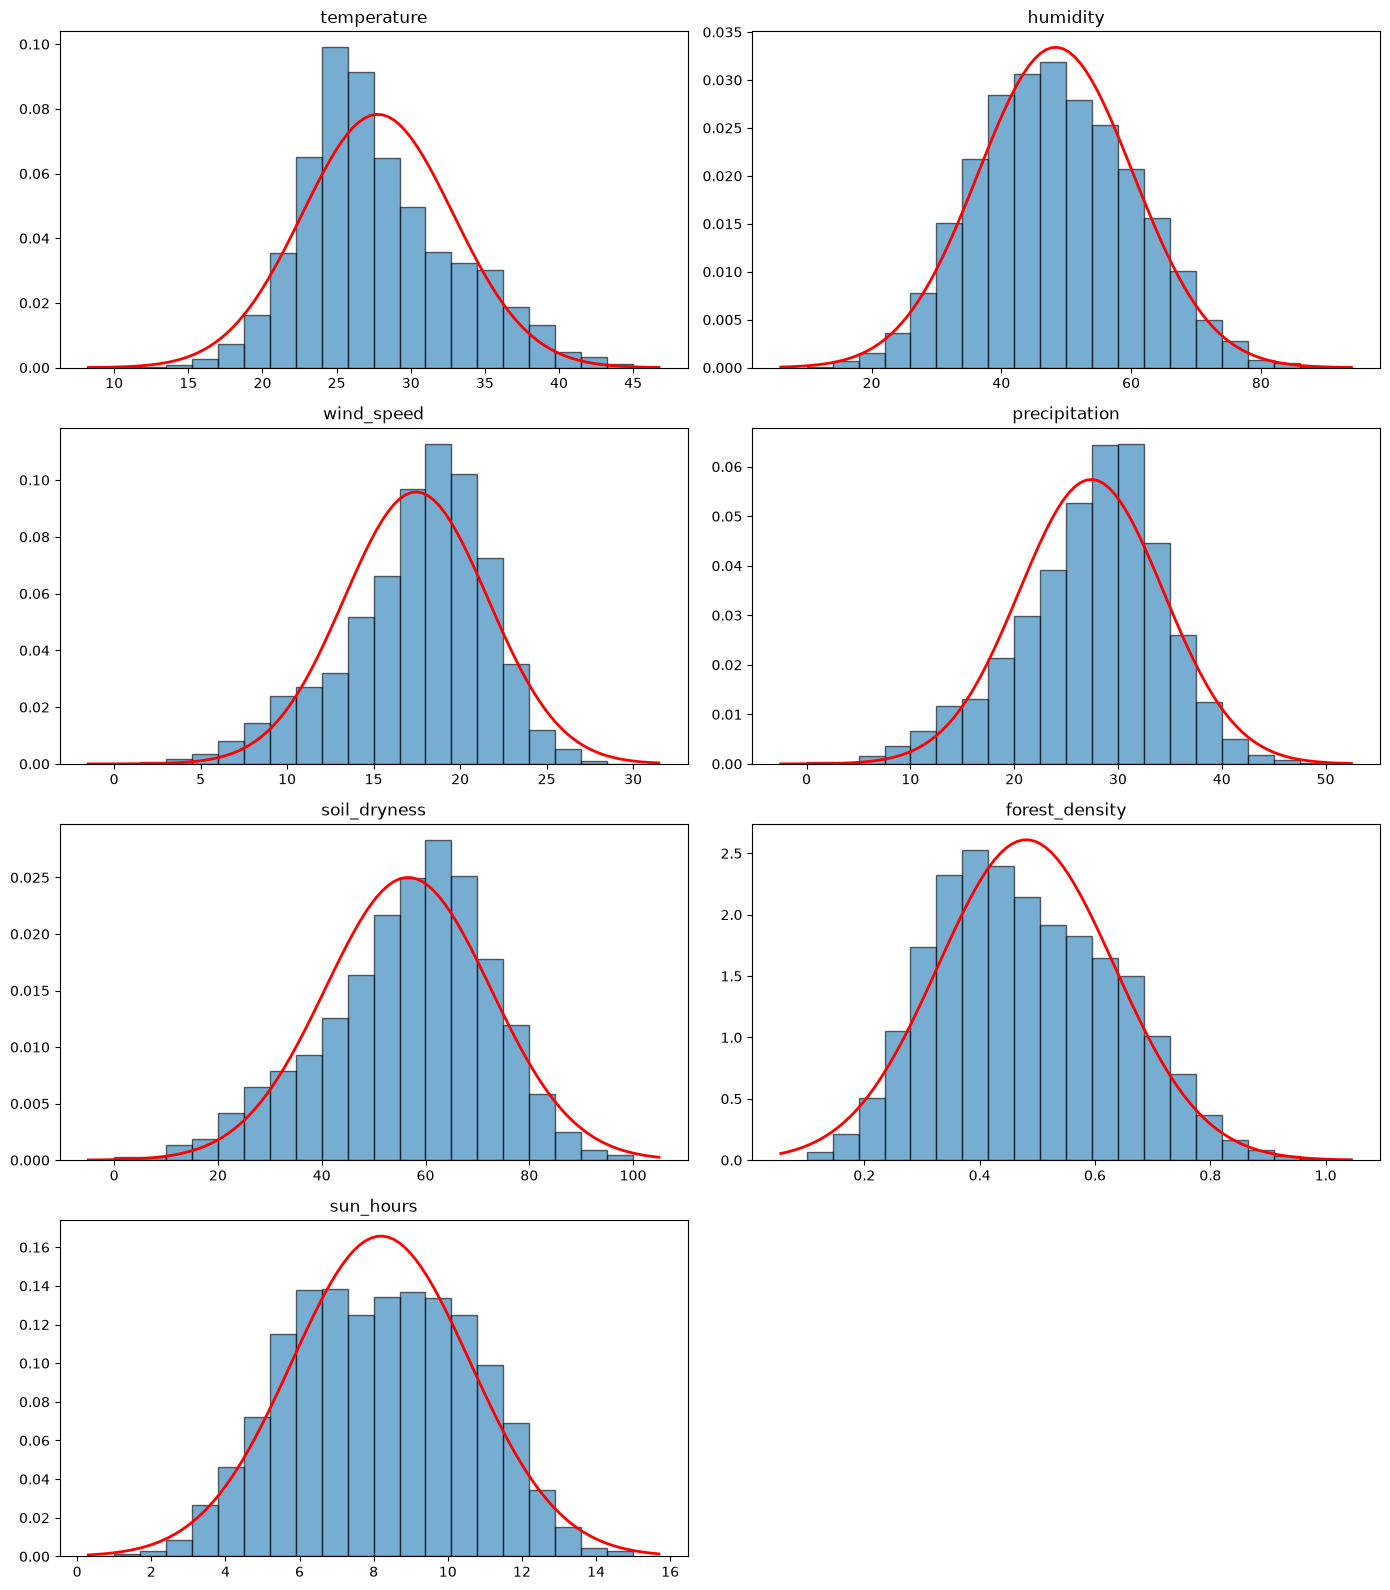

In [15]:
import scipy.stats as stats 

columnas_numericas = df.select_dtypes(include=["float64", "int64"]).columns # seleccionar solo las columnas numéricas del DataFrame

# Grid de subplots, de 4 filas y 2 columnas
filas = 4
columnas = 2

# Crear la figura y los ejes
fig, axes = plt.subplots(filas, columnas, figsize=(14, 16))
axes = axes.flatten()

# Bucle para iterar sobre las columnas numéricas y crear histogramas con la distribución normal superpuesta
for i, col in enumerate(columnas_numericas):
    ax = axes[i] # seleccionar el eje correspondiente para cada columna
    data = df[col].dropna() # eliminar valores nulos para evitar errores en la estimación de la distribución normal

    ax.hist(data, bins=20, density=True, alpha=0.6, edgecolor='black') # configuración del histograma
    xmin, xmax = ax.get_xlim() # obtener los límites del eje x para la distribución normal
    x = np.linspace(xmin, xmax, 100) # rangos de valores para la distribución normal
    p = stats.norm.pdf(x, data.mean(), data.std()) # cálculo de la distribución normal
    ax.plot(x, p, 'r', linewidth=2) # superponer la distribución normal en rojo
    ax.set_title(col) # establecer el título del subplot con el nombre de la columna

# Elimina gráficos vacíos si hay menos de filas * columnas
for j in range(len(columnas_numericas), len(axes)):
    fig.delaxes(axes[j]) # eliminar ejes vacíos que cumplan la condición del bucle

plt.tight_layout()
plt.show()

##### Comprobación de la distribución de la información.    

En general, las variables del conjunto de datos presentan una separación moderada entre las clases `fire` y `no_fire`, aunque con cierta superposición en la mayoría de casos.    

Variables como `temperature`, `humidity`, `wind_speed`, `precipitation`, `soil_dryness` y `forest_density` muestran patrones distintos según la presencia de incendios, lo que indica su potencial utilidad para la predicción.     

En cambio, `sun_hours` presenta distribuciones muy similares entre clases y parece tener un valor predictivo limitado de forma individual. Aun así, la combinación de todas las variables podría aportar información complementaria que mejore el rendimiento de los modelos de clasificación.   

Esto también se puede comprobar en los gráficos siguientes, en los que separamos las distribuciones de cada característica relacionándola con el valor de la variable objetivo (*`'fire'`*)

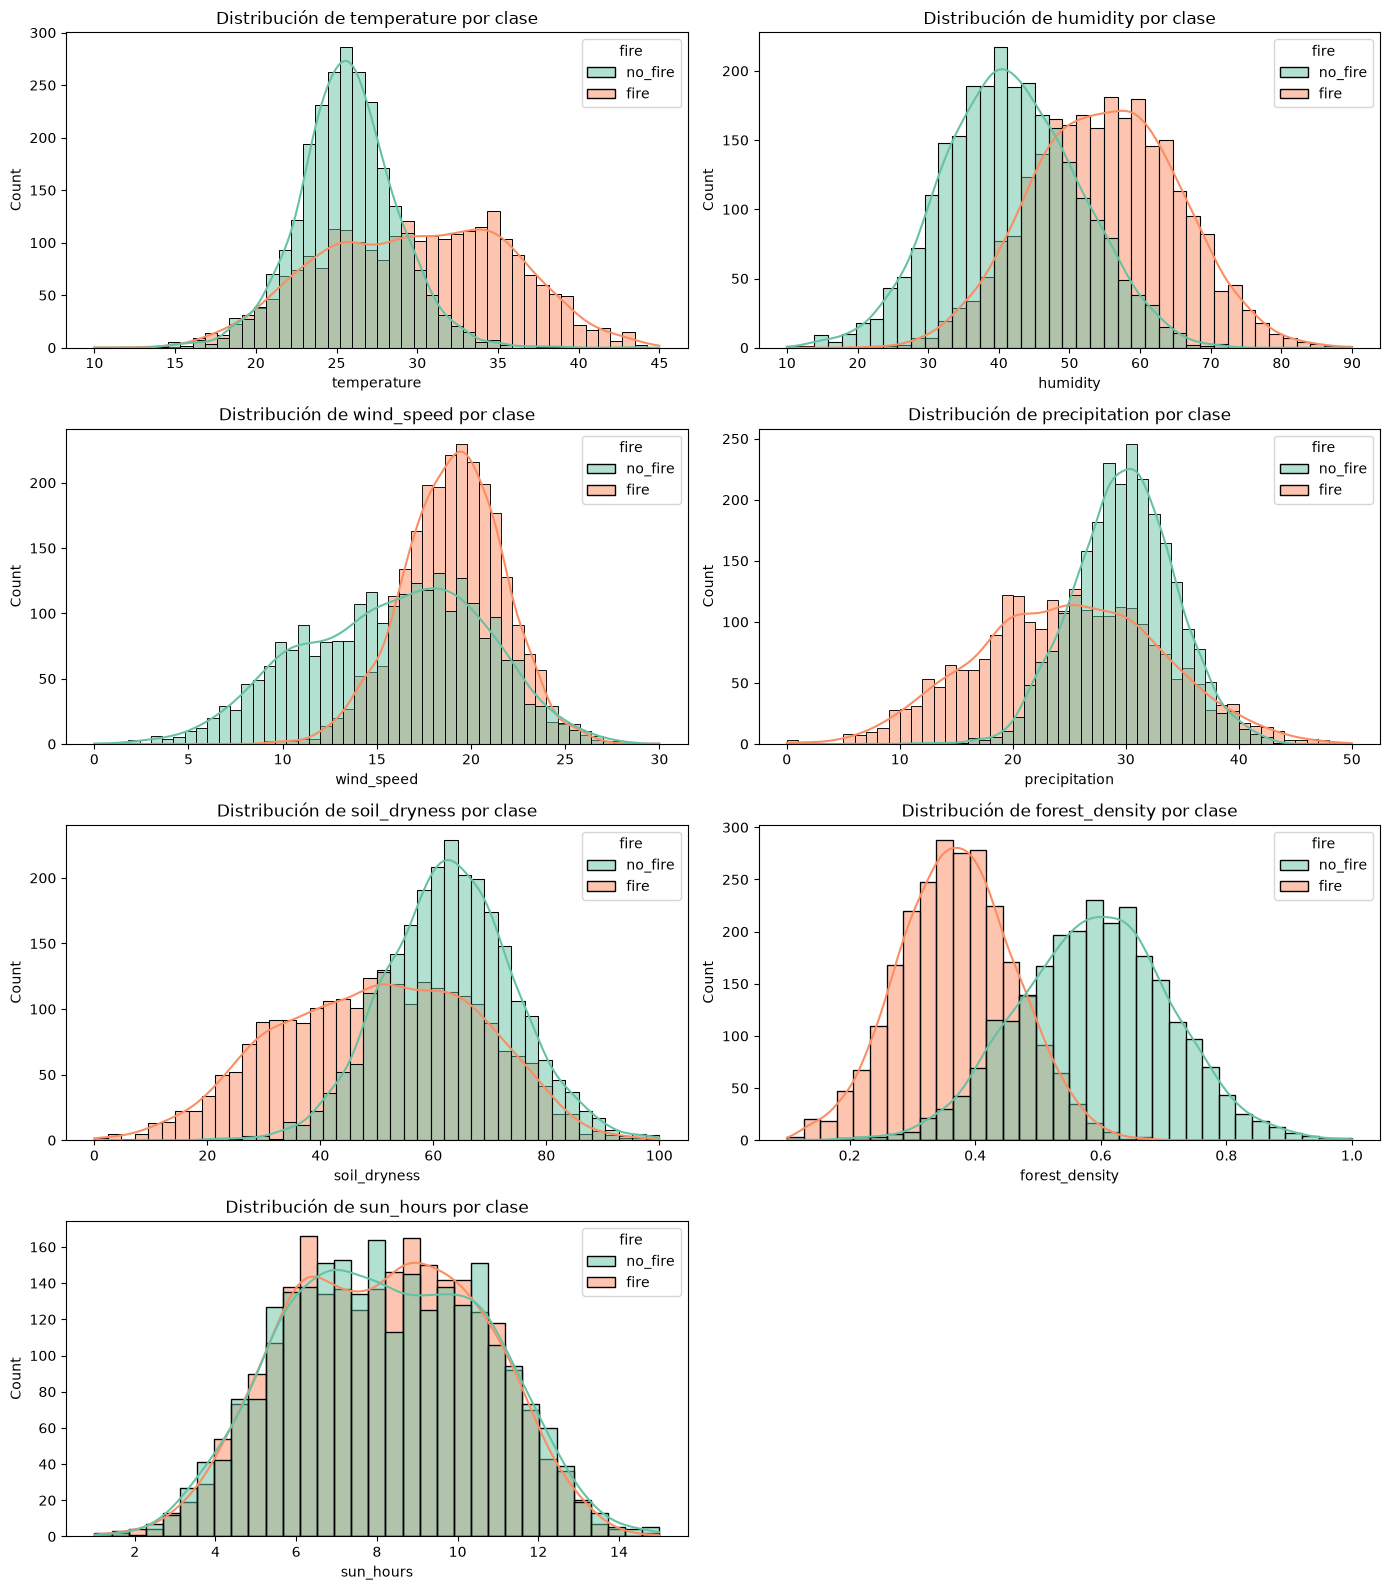

In [ ]:
import math

caracteristicas = df.columns[:-1] # seleccion de todas las columnas excepto la última (fire) como características para los gráficos
num_graficos = len(caracteristicas) # número total de gráficos a crear

columnas = 2
filas = math.ceil(num_graficos / columnas) # cálculo del número de filas necesarias para acomodar todos los gráficos en un grid de 2 columnas

fig, axes = plt.subplots(filas, columnas, figsize=(14, filas * 4))
axes = axes.flatten()

for i, caracteristica in enumerate(caracteristicas):
    sns.histplot(data=df, x=caracteristica, hue='fire', kde=True, palette='Set2', ax=axes[i])
    axes[i].set_title(f"Distribución de {caracteristica} por clase")
    axes[i].set_xlabel(caracteristica)
    axes[i].set_ylabel("Count")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout() # Ajuste automático del espaciado entre subplots para evitar solapamientos
plt.show()

#### 9.- Análisis de correlaciones.

In [17]:
# Convierte la variable objetivo a 0 y 1, para que sea compatible con los modelos de clasificación
df['fire'] = df['fire'].map({'fire': 1, 'no_fire': 0})

##### Se muestra la correlación entre cada variable numérica y la variable objetivo

La variable más relacionada con los incendios es la **densidad forestal**, que muestra una relación inversa clara. También destacan la **humedad** y la **temperatura**, que se asocian positivamente con la aparición de incendios. El **viento**, la **sequedad del suelo** y la **precipitación** tienen una influencia más moderada. En cambio, las **horas de sol** apenas muestran relación con la variable objetivo.

In [18]:
correlaciones = df.select_dtypes(include=["float64", "int64"]).corr()["fire"].drop("fire")
print(correlaciones)

temperature       0.414614
humidity          0.557801
wind_speed        0.382591
precipitation    -0.355702
soil_dryness     -0.394039
forest_density   -0.716505
sun_hours        -0.006745
Name: fire, dtype: float64


##### Matriz de correlación (HeatMap)

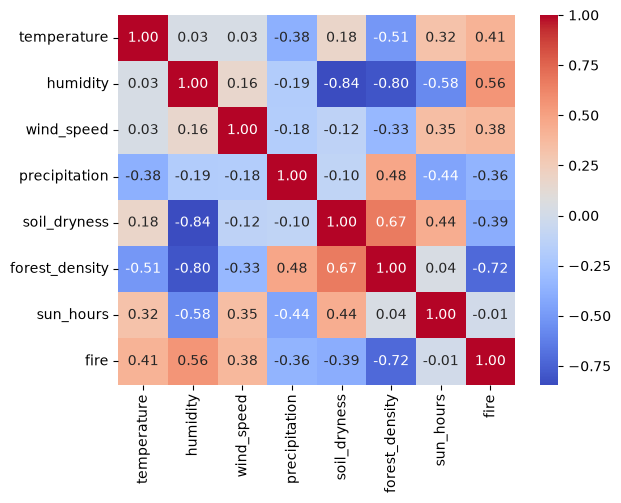

In [20]:
matriz_correlacion = df.select_dtypes(include=["float64", "int64"]).corr()
heatmap = sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".2f")

En base a los valores obtenidos, podemos interpretar que cuando, por ejemplo, cuanto mayor es la **densidad forestal**, menos incendios hay, según estos datos: cuando `forest_density` sube, `fire` tiende a bajar.   

Otro valor que afecta, como ya se ha dicho, es la *humedad* (`humidity`), con un valor aproximado de *0,56*.

##### Gráfica comprobación balance de datos.      

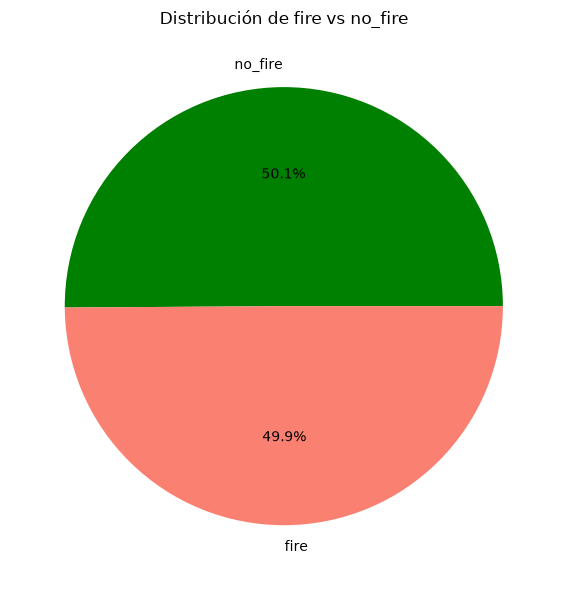

In [23]:
plt.figure(figsize=(6, 6))
df['fire'].map({0: 'no_fire', 1: 'fire'}).value_counts().plot.pie(autopct='%1.1f%%', colors=['green', 'salmon'])
plt.title('Distribución de fire vs no_fire')
plt.ylabel("")
plt.tight_layout()
plt.show()

Se observa que el número de muestras, a nivel porcentual, está muy bien balanceado.

#### 10.- Gestión de Outliers.

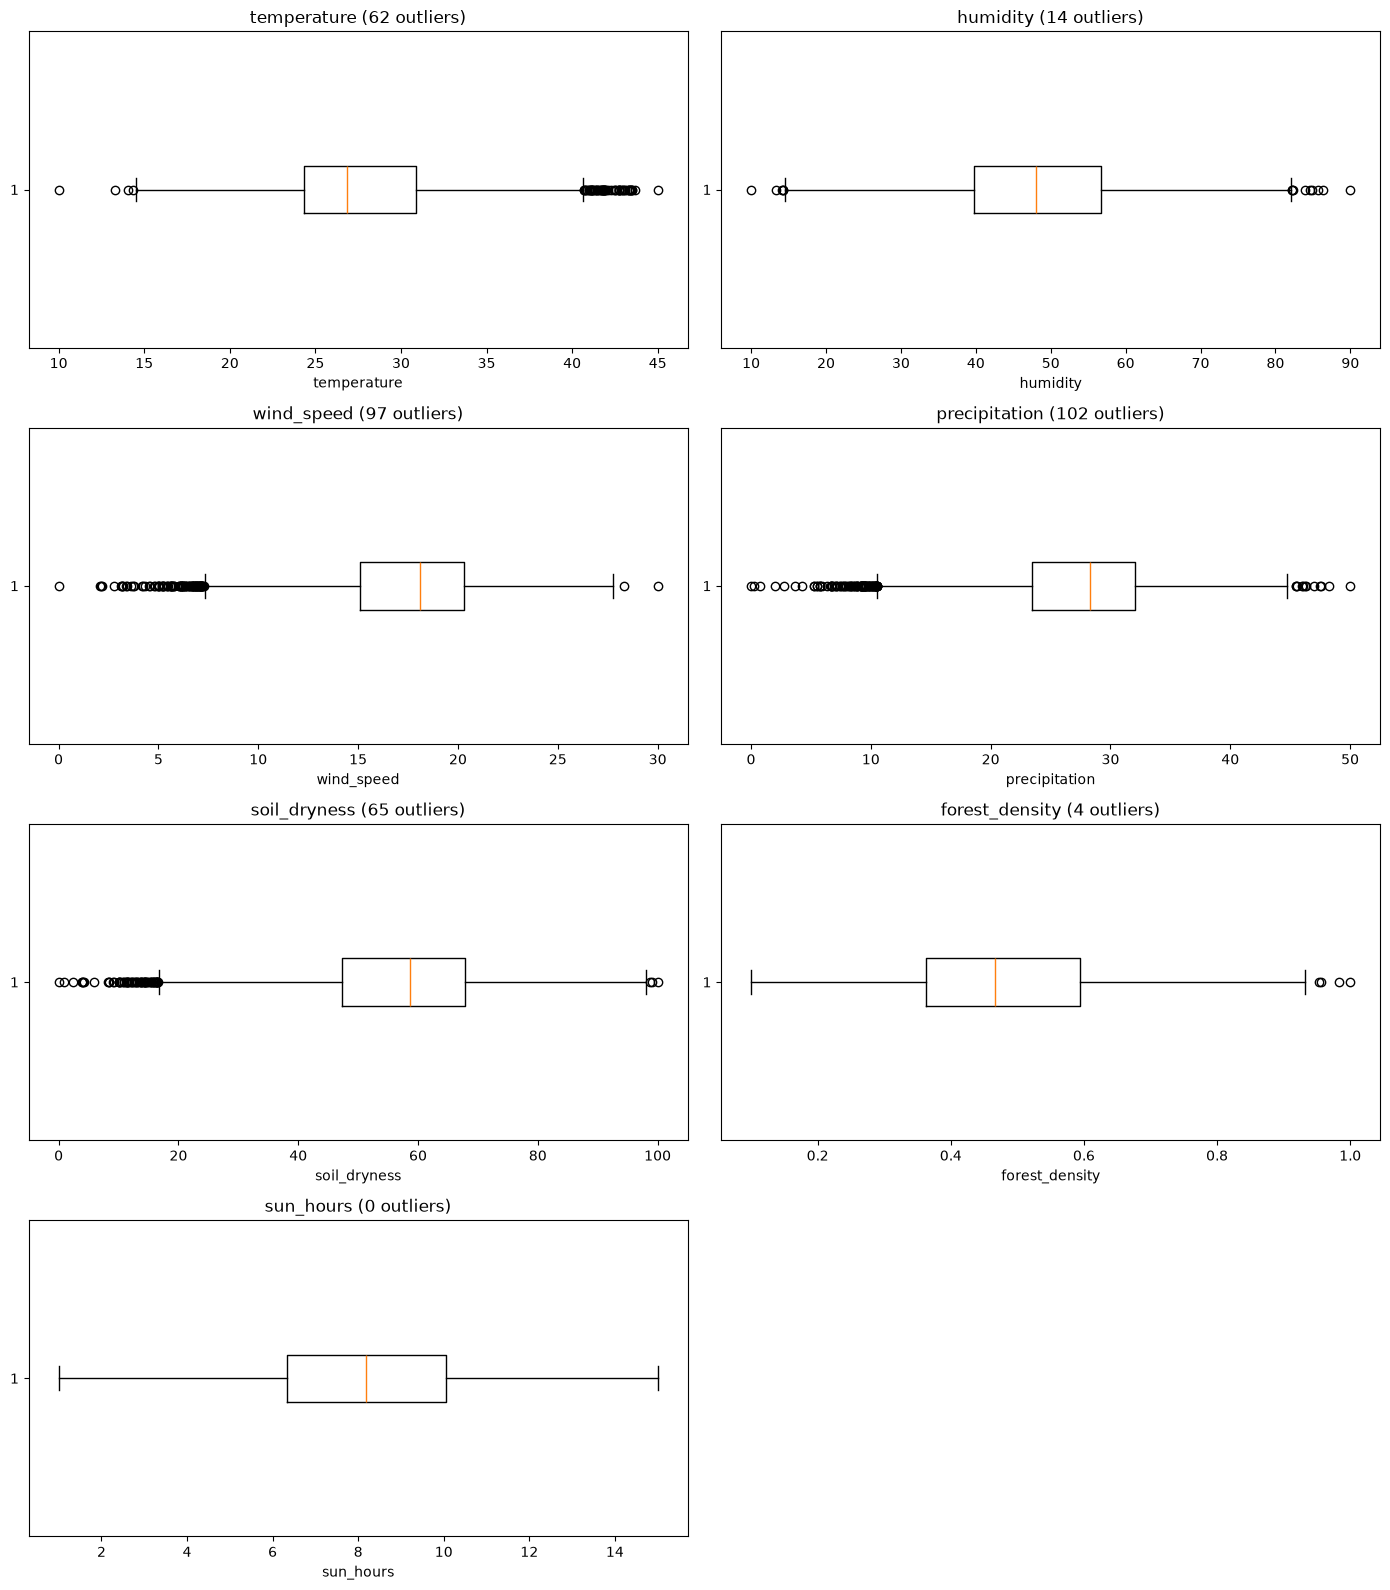

In [ ]:
columnas_numericas = df.select_dtypes(include=["float64", "int64"]).columns.drop("fire")

outliers = {}

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(columnas_numericas):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    # para calcular los límites usamos el rango intercuartílico (IQR) y multiplicamos por 1.5, que es un valor comúnmente utilizado para detectar outliers.
    lim_inf = Q1 - 1.5 * IQR 
    lim_sup = Q3 + 1.5 * IQR
    # aplicamos los límites para contar el número de outliers en cada columna, que son los que superan los límites inferior o superior.
    n_outliers = df[(df[col] < lim_inf) | (df[col] > lim_sup)].shape[0]
    outliers[col] = n_outliers

    axes[i].boxplot(df[col], vert=False)
    axes[i].set_title(f"{col} ({n_outliers} outliers)")
    axes[i].set_xlabel(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Inicialmente, no se eliminan outliers porque el número es bajo en relación con el total de observaciones y algunas variables como `wind_speed` o `precipitation` podrían tener valores extremos informativos.    

Además, se *normalizarán* sus valores para reducir su impacto en los modelos.

### División en conjunto de entrenamiento y de test

In [27]:
# División previa de los datos del dataframe. X serán las características e y será la columna objetivo
X = df.drop('fire', axis=1)
y = df['fire']

In [ ]:
# División de los datos en entrenamiento (70%) y test (30%). Semilla aleatoria para reproducibilidad
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42) 

### Correlación entre características

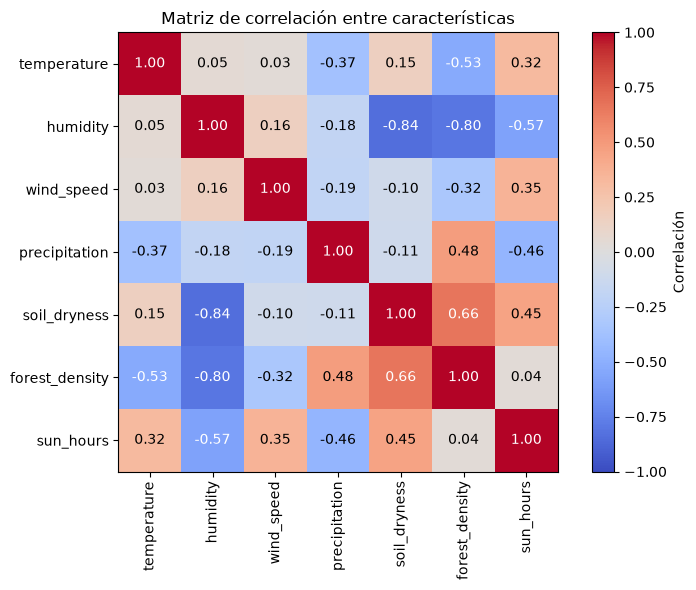

In [32]:
import matplotlib.pyplot as plt

correlation_matrix = X_train.corr()

plt.figure(figsize=(8, 6))
plt.imshow(correlation_matrix, cmap="coolwarm", interpolation="none", vmin=-1, vmax=1)
plt.colorbar(label="Correlación")

cols = X_train.columns
plt.xticks(range(len(cols)), cols, rotation=90)
plt.yticks(range(len(cols)), cols)

for i in range(len(cols)):
    for j in range(len(cols)):
        value = correlation_matrix.iloc[i, j]
        color = 'white' if abs(value) > 0.5 else 'black'
        plt.text(j, i, f"{value:.2f}", ha='center', va='center', color=color, fontsize=10)

plt.title("Matriz de correlación entre características")
plt.tight_layout()
plt.show()

La matriz muestra correlaciones fuertes entre `humidity`, `soil_dryness` y `forest_density`, lo que indica posibles redundancias entre estas variables.    

El resto de variables presentan correlaciones bajas, por lo que aportan información independiente.    

De momento, no es necesario eliminar ninguna variable, pero conviene tener en cuenta estas relaciones si se optase por modelos sensibles a la '*multicolinealidad*'.

### Escalado de variables con rangos más amplios    

Se aplica `MinMaxScaler` para regularizar las variables que tienen rangos distintos y no siguen una distribución normal.

In [33]:
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

`MinMaxScaler` (`scikit-learn`) es una técnica de escalado simple que transforma las características de un conjunto de datos en un rango específico. Esta transformación garantiza que cada característica de los datos esté dentro del mismo rango, generalmente entre 0 y 1.   

Funcionamiento de `MinMaxScaler`:      

*PASO 1.*       
Cuando llamamos `fit_transform` con los datos de entrenamiento, `MinMaxScaler` realiza dos operaciones:   
- *Ajuste*: calcula los valores *mínimo* y *máximo* de cada característica(columna) en los datos de entrenamiento. Estos valores se almacenan internamente en la instancia del escalador.    
Por ejemplo:   
        `scaler.data_min_`:El valor mínimo para cada característica.     
        `scaler.data_max_`:El valor máximo para cada característica.
- *Transformar*: el escalador aplica los valores mínimo y máximo que acaba de calcular para escalar los datos de entrenamiento. Cada característica del conjunto de entrenamiento se transforma de acuerdo con la fórmula mencionada anteriormente.        

*PASO 2*    
Cuando transformamos los datos de prueba con `scaler.transform()`, `MinMaxScaler` utiliza los valores mínimo y máximo que se calcularon a partir de los datos de entrenamiento para escalar los datos de prueba.    
No vuelve a calcular nuevos valores mínimo y máximo para los datos de prueba. En cambio, utiliza los valores y almacenados `scaler.data_min_` y `scaler.data_max_` del paso de entrenamiento.     
Esto garantiza que los datos de prueba se transformen de la misma manera que los datos de entrenamiento, manteniendo la escala consistente.

## Aplicación del modelo usando k-NN

In [ ]:
# Inicialización del clasificador (k=5, que es un valor comúnmente utilizado)
clasificador_KNN = KNeighborsClassifier(n_neighbors=5, metric='euclidean') # por defecto, la métrica que trae el clasificador es la distancia minkowski.

# Entrenamiento del clasificador
clasificador_KNN.fit(X_train, y_train)

,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [36]:
# Realización de las predicciones
predicciones_KNN = clasificador_KNN.predict(X_test)

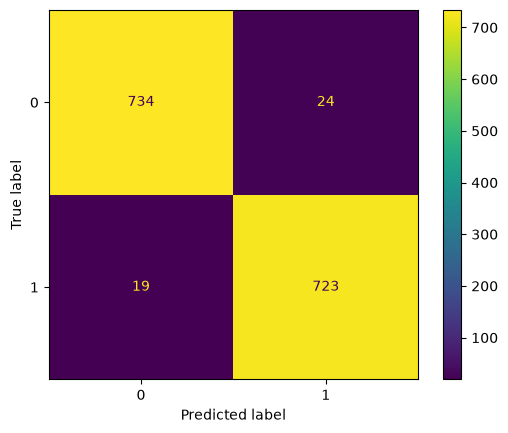

In [ ]:
# Creación de la matriz de confusión
ConfusionMatrixDisplay.from_predictions(y_test, predicciones_KNN); #resultado real frente a las predicciones del modelo

##### Métricas de evaluación

In [40]:
accuracy_KNN = accuracy_score(y_test, predicciones_KNN)
precision_KNN = precision_score(y_test, predicciones_KNN, average='weighted')
exactitud=accuracy_KNN *100 
precision=precision_KNN *100
print(f"Exactitud: {exactitud:.2f} %")
print(f"Precisión: {precision:.2f} %")

Exactitud: 97.13 %
Precisión: 97.14 %


Vemos, en este caso, que el modelo es bastante preciso en la clasificación que debe realizar, ya que tanto `accuracy`como `precision` toman valores por encima del 97 %.